### Make mesh for both ERT and RST and filters data

- ERT and RST topo start has to match, script then cuts ERT to RST "size"
- all data files (ERT and RST in txt/dat) have to be in path defined below
- profile name has to be defined below

All rights reserved. Material from GEOFCAN 2025 Workshop led by Coline Mollaret

In [1]:
import time 
t = time.time() # get current time to check the time to run the script

In [2]:
#############################################
# Import packages
#############################################

import sys, os
from pathlib import Path
# try and except functions to change the directory only once to stay in the right folder even the script/cell is run again
try:  findpaths
except NameError:  
    os.chdir(os.path.abspath("..")) #to find the folder where the data are stored
    findpaths=True
print(os.getcwd()) #print the current working directory
#############################################

import numpy as np
import pygimli as pg
pg.verbose = print # temporary
import pygimli.meshtools as mt
import shutil
import matplotlib.pyplot as plt
from pygimli.physics import ert

import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR) # to get rid of "matplotlib.font_manager - WARNING - findfont: Font family 'Roboto' not found."


/home/jovyan/work/4pm-pji


### Profile name selection

The following profile names are available in the folder pji/data.

Both electrical resistivity data (*_profile_*_rhoa.txt) and P wave travel time data (*_profile_*_tt.txt) are needed.

In [3]:
### SELECT YOUR PROFILE NAME ##########################################
#profile='CH_COR_V01_2007-07-13_01' # choose profile name 
#profile='CH_DOL_V01_2016-08-11_01'
profile='CH_LAP_MH1_2010-08-24_01'
#profile = 'KG_ABR_P03_2021-08-22_01'
#profile='3L'

print("profile: " + profile)

###############################################################################
# Import profile specific settings if they exist, otherwise import default settings:
if os.path.exists(os.path.abspath('profile_settings/'+profile+'_settings.py')):
    exec(open('profile_settings/'+profile+'_settings.py', 'r').read()) # reads site specific settings
    print('profile settings exist and were loaded at: pji/profile_settings/'+profile+'_settings.py')
    print("\nDon't forget to adapt the settings according to your profile!")
else:
    from settings import *
    print('profile settings do not exist, default was loaded')

##### Creates new directories if not existing yet
Path(os.getcwd()+'/results/filtered_data/').mkdir(parents=True, exist_ok=True)
Path(os.getcwd()+'/results/mesh/').mkdir(parents=True, exist_ok=True)

profile: CH_LAP_MH1_2010-08-24_01
profile settings exist and were loaded at: pji/profile_settings/CH_LAP_MH1_2010-08-24_01_settings.py

Don't forget to adapt the settings according to your profile!


### Load ERT and RST data

In [4]:
### load ERT data #######
#########################
ertData = pg.DataContainerERT('data/' + profile+ '_rhoa.txt')
print("Number of electrodes:", ertData.sensorCount())
print(ertData)

### load RST data  ######
#########################
rstData = pg.DataContainer('data/' + profile+ '_tt.txt', "s g")
print("Number of shot/receivers:", rstData.sensorCount())
maxrst = pg.max(pg.x(rstData.sensors()))

##############################################################################
# Filter data, make both datasets same length (cut ERT data to fit RST)

### ERT data preparation
#########################
idx = []
for i, sensor in enumerate(ertData.sensors()):
    if sensor[0] >= maxrst:
        idx.append(i)

#Removes sensors from ertData that are not covered by RST so that both datasets are same
ertData.removeSensorIdx(idx)
ertData.removeInvalid()
ertData.removeUnusedSensors()

# Attribute the resistivity measurement error erte defined in the settings file
ertData.set("err", pg.Vector(ertData.size(), erte))

# compute the geometric factor k and the apprent resistivity rhoa
ertData['k'] = ert.createGeometricFactors(ertData, numerical=True)
if max(ertData["r"]) > 0:
    ertData['rhoa'] = ertData["r"] * ertData["k"]
    print('\nResistance value available, rhoa is computed from r and k\n')
else:
    print('\nNo resistance value available, rhoa is not computed from r\n')

ertData.save('results/filtered_data/' + profile + "_ert_filtered.data")
print(ertData)

# RST data preparation
#########################
# Attribute the seismic measurement error rste defined in the settings file
rstData.set("err", pg.Vector(rstData.size(), rste))
print(rstData)

# Calculate offset between shot and geophones
px = pg.x(rstData.sensorPositions())
gx = np.array([px[int(g)] for g in rstData("g")])
sx = np.array([px[int(s)] for s in rstData("s")])
offset = np.absolute(gx - sx)
va = offset / rstData("t")

rstData.markInvalid(rstData("s") == rstData("g")) # Remove positions where shot is equal to geophone, because simulated traveltime will always be zero.
rstData.markInvalid(rstData("t") == 0) # Remove positions where shot is equal to geophone, because simulated traveltime will always be zero.
rstData.removeInvalid()
rstData.save('results/filtered_data/' + profile + "_rst_filtered.data")

13/10/25 - 10:51:41 - pyGIMLi - INFO - Cache /opt/conda/lib/python3.10/site-packages/pygimli/physics/ert/ert.py:createGeometricFactors restored (1.1s x 1): /home/jovyan/.cache/pygimli/4804055849860715051


Number of electrodes: 47
Data: Sensors: 47 data: 276, nonzero entries: ['a', 'b', 'err', 'i', 'm', 'n', 'r', 'u', 'valid']
Number of shot/receivers: 49

Resistance value available, rhoa is computed from r and k

Data: Sensors: 43 data: 276, nonzero entries: ['a', 'b', 'err', 'i', 'k', 'm', 'n', 'r', 'rhoa', 'u', 'valid']
Data: Sensors: 49 data: 573, nonzero entries: ['err', 'g', 's', 't', 'valid']


/tmp/ipykernel_1110/1104167325.py:53: RuntimeWarning: invalid value encountered in divide
  va = offset / rstData("t")


1

In [5]:
# Combined sensor positions from both methods to create a common mesh
##################################################################################
rstData = pg.DataContainer('results/filtered_data/' +profile + "_rst_filtered.data", "s g")
ertData = pg.DataContainerERT('results/filtered_data/' +profile + "_ert_filtered.data")
print(ertData)

print(len(ertData.sensorPositions()))
#for pos in ertData.sensorPositions():
#    print(pos)

def is_close(pos, data, tolerance=0.1):
    for posi in data.sensorPositions():
        dist = pos.dist(posi)
        if dist <= tolerance:
            return True
    return False

combinedSensors = pg.DataContainer()
for pos in ertData.sensorPositions():
    combinedSensors.createSensor(pos)

for pos in rstData.sensorPositions():
    if not is_close(pos, ertData):
        combinedSensors.createSensor(pos)
    #else:
    #    print("Not adding", pos)

combinedSensors.sortSensorsX()
x = pg.x(combinedSensors.sensorPositions()).array()
z = pg.z(combinedSensors.sensorPositions()).array()

np.savetxt('results/mesh/' +profile +"_sensors.npy", np.column_stack((x, z)))

print("Number of combined positions:", combinedSensors.sensorCount())
print(combinedSensors)

# mesh parameters definition
try: paraDX  # if paraDX not existing (in the setting file), then use the default value
except NameError: paraDX = 0.5  # by default (if not defined in settings!)
    
try: paraMaxCellSize # Max cell size
except NameError: paraMaxCellSize = 20 # by default (if not defined in settings!)

plc = mt.createParaMeshPLC(combinedSensors, paraDX=paraDX, boundary=boundary,
                           paraDepth=paraDepth, paraBoundary=paraBoundary,paraMaxCellSize=paraMaxCellSize)

mesh = mt.createMesh(plc, quality=33.8)

Data: Sensors: 43 data: 276, nonzero entries: ['a', 'b', 'err', 'i', 'k', 'm', 'n', 'r', 'rhoa', 'u', 'valid']
43
Number of combined positions: 49
Data: Sensors: 49 data: 0, nonzero entries: []
pzeAq33.8aQ


plot of the outer domain (mesh) for the ERT forward simulation:


(<Axes: >, None)

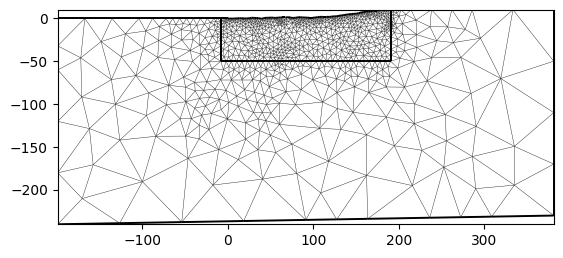

In [6]:
### Save and plot
######################

mesh.save('results/mesh/' + profile + "_mesh.bms")

# Extract inner domain where parameters should be estimated.
# Outer domain is only needed for ERT forward simulation,
# not for seismic traveltime calculations.
paraDomain = pg.Mesh(2)
paraDomain.createMeshByMarker(mesh, 2)
paraDomain.save('results/mesh/' + profile +'_paraDomain')
print("plot of the outer domain (mesh) for the ERT forward simulation:")
pg.show(mesh)



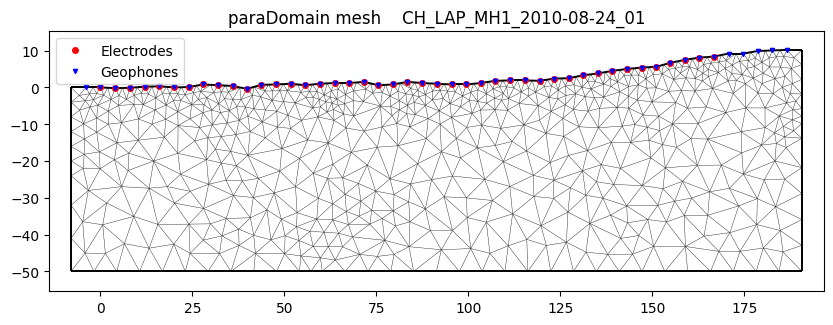

In [7]:
# Plot and save paraDomain mesh
######################
fig, ax = plt.subplots(figsize=(10, 6))
pg.show(paraDomain, showMesh=True, markers=False, ax=ax, hold=True)
ax.set_xlim(x[0] - 10, x[-1] + 10)
ax.set_ylim(min(z) - paraDepth -5, max(z) + 5)
ax.set_title('paraDomain mesh    '+profile)
ax.plot(pg.x(ertData.sensorPositions()), pg.z(ertData.sensorPositions()), "ro", ms=4, label="Electrodes")
ax.plot(pg.x(rstData.sensorPositions()), pg.z(rstData.sensorPositions()), "bv", ms=3, label="Geophones")
ax.legend()
fig.savefig('results/mesh/' + profile + "_mesh_with_sensors.png")



In [8]:
# Mesh length
print("mesh      :",mesh)
print("paraDomain:", paraDomain)
print(paraDepth)

mesh      : Mesh: Nodes: 957 Cells: 1773 Boundaries: 2729
paraDomain: Mesh: Nodes: 671 Cells: 1188 Boundaries: 1858
50


In [9]:
print("elapsed = ", time.time() - t)

elapsed =  0.9232051372528076
